# Business problem statement

A leading financial institution wants to develop an intelligent Anti-Money Laundering detection system using Artificial Neural Networks to identify suspicious financial transactions. The existing rule-based system generates a large number of false alerts and fails to detect sophisticated money laundering patterns. The bank wants to leverage historical transaction data and customer behavioral patterns to build a predictive model that can classify transactions as legitimate or suspicious, thereby improving detection rates, reducing false positives, and supporting regulatory compliance

# Project Objective

The primary objective is to build a binary classification model using ANN to identify potentially suspicious financial transactions.

Technical objectives:
1. Analyze historical banking transaction data.
2. Perform exploratory data analysis (EDA).
3. Identify important transaction-level and customer-level features.
4. Handle missing values and categorical variables.
5. Apply feature scaling and preprocessing.
6. Handle imbalanced transaction classes.
7. Build an ANN architecture using TensorFlow/Keras.
8. Train the model to distinguish legitimate and suspicious transactions.
9. Optimize the model using hyperparameter tuning.
10. Evaluate the model using appropriate classification metrics.
11. Develop a prediction interface for real-time transaction monitoring.

# Expected business outcomes

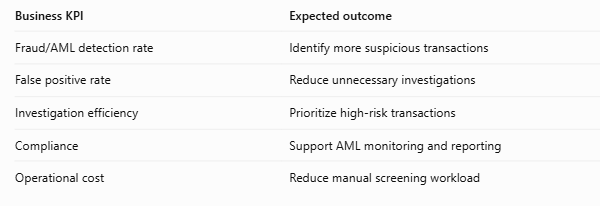

# Constraints

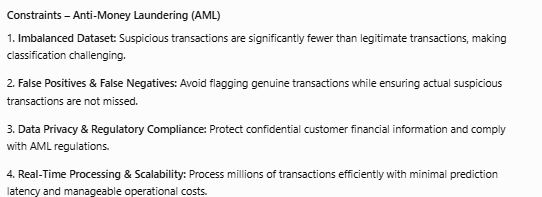

# 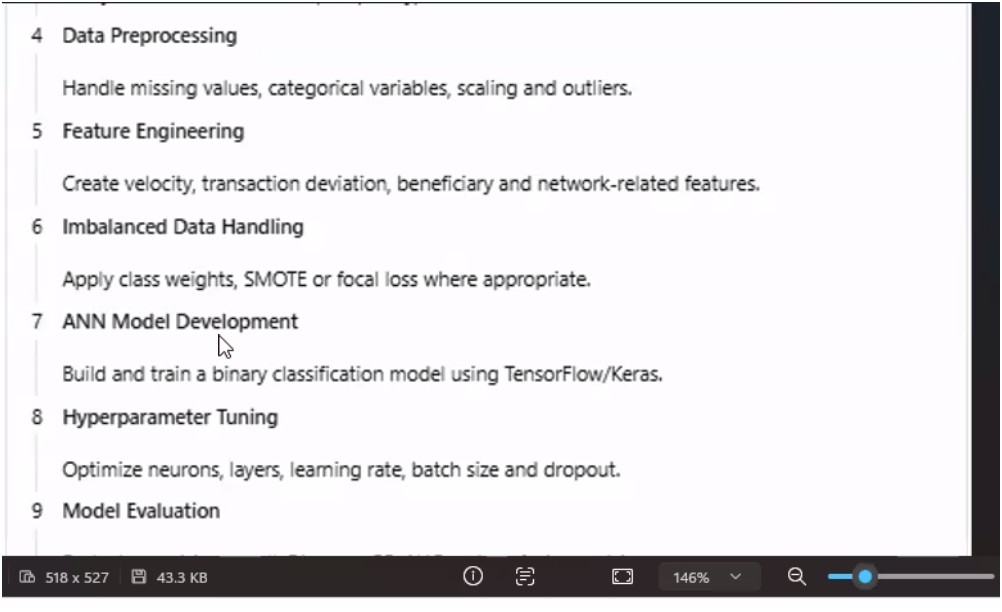

# 1b) Data Unerstanding 
Data Collection 


In [3]:
!pip install Kagglehub


  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
Using cached certifi-2026.10.23-py3-none-any.whl (135 kB)

  Attempting uninstall: certifi

    Found existing installation: certifi 2026.7.22

    Uninstalling certifi-2026.7.22:

      Successfully uninstalled certifi-2026.7.22

   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   -------------------------- ------------- 2/3 [Kagglehub]
   ---------------------------------------- 3/3 [Kagglehub]



ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [28]:
import kagglehub
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
import kagglehub

# Download dataset
path = kagglehub.dataset_download(
    "berkanoztas/synthetic-transaction-monitoring-dataset-aml",
    force_download=True
)

print("Dataset downloaded to:", path)

100%|███████████████████████████████████████████████████████████████████████████████| 193M/193M [00:57<00:00, 3.55MB/s]

Extracting files...


Dataset downloaded to: C:\Users\vicky\.cache\kagglehub\datasets\berkanoztas\synthetic-transaction-monitoring-dataset-aml\versions\2


# 2.) Data Descrption
# a. Exploratory Data Analysis 
1. Univarient analysis

In [29]:
import pandas as pd

In [30]:
df = pd.read_csv(r"C:\Users\vicky\.cache\kagglehub\datasets\berkanoztas\synthetic-transaction-monitoring-dataset-aml\versions\2\SAML-D.csv")

In [31]:
df

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
...,...,...,...,...,...,...,...,...,...,...,...,...
9504847,10:57:01,2023-08-23,2453933570,519744068,2247.25,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Small_Fan_Out
9504848,10:57:06,2023-08-23,9805510177,5416607878,927.18,UK pounds,UK pounds,UK,UK,Debit card,0,Normal_Small_Fan_Out
9504849,10:57:06,2023-08-23,7282330957,2995527149,1455.14,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Small_Fan_Out
9504850,10:57:11,2023-08-23,940337377,4812815165,25995.70,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In


In [32]:
df.shape

(9504852, 12)

In [33]:
df.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


# The dataset incorporates 12 features and 28 typologies (split between 11 normal and 17 suspicious). These were selected based on existing datasets, the academic literature, and interviews with AML specialists. The dataset comprises 9,504,852 transactions, of which 0.1039% are suspicious. It also includes 15 graphical network structures to represent the transaction flow within these typologies. The structures, while sometimes shared among typologies, vary significantly in parameters to increase complexities and challenge detection efforts. More details about these typologies are available in the paper above. The dataset is an updated version compared to the paper.

Features of the SAML-D dataset:

• Time and Date: Essential for tracking transaction chronology.

• Sender and Receiver Account Details: Helps uncover behavioural patterns and complex banking connections.

• Amount: Indicates transaction values to identify suspicious activities.

• Payment Type: Includes various methods like credit card, debit card, cash, ACH transfers, cross-border, and cheque.

• Sender and Receiver Bank Location: Pinpoints high-risk regions including Mexico, Turkey, Morocco, and the UAE.

• Payment and Receiver Currency: Align with location features, adding complexity when mismatched.

• 'Is Suspicious' Feature: Binary indicator differentiating normal from suspicious transactions.

• Type: Classifies typologies, offering deeper insights.

** Outputs ** - Is_laudering,Laundering_type
**inputs ** Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9504852 entries, 0 to 9504851
Data columns (total 12 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   Time                    object 
 1   Date                    object 
 2   Sender_account          int64  
 3   Receiver_account        int64  
 4   Amount                  float64
 5   Payment_currency        object 
 6   Received_currency       object 
 7   Sender_bank_location    object 
 8   Receiver_bank_location  object 
 9   Payment_type            object 
 10  Is_laundering           int64  
 11  Laundering_type         object 
dtypes: float64(1), int64(3), object(8)
memory usage: 870.2+ MB


# Data Preparation
1. Exploratory Data Analysis

In [35]:
df.isna().sum()

Time                      0
Date                      0
Sender_account            0
Receiver_account          0
Amount                    0
Payment_currency          0
Received_currency         0
Sender_bank_location      0
Receiver_bank_location    0
Payment_type              0
Is_laundering             0
Laundering_type           0
dtype: int64

In [36]:
df.duplicated().sum()

np.int64(0)

In [37]:
df.describe()

,Sender_account,Receiver_account,Amount,Is_laundering
count,9.504852e+06,9.504852e+06,9.504852e+06,9.504852e+06
mean,5.006619e+09,5.006006e+09,8.762968e+03,1.038733e-03
std,2.885814e+09,2.884763e+09,2.561495e+04,3.221263e-02
min,9.018000e+03,9.018000e+03,3.730000e+00,0.000000e+00
25%,2.513133e+09,2.513219e+09,2.143688e+03,0.000000e+00
50%,5.001017e+09,5.002572e+09,6.113720e+03,0.000000e+00
75%,7.505051e+09,7.502397e+09,1.045846e+04,0.000000e+00
max,9.999987e+09,9.999971e+09,1.261850e+07,1.000000e+00


In [38]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

In [39]:
df['Amount'].mean()

np.float64(8762.967600927232)

In [40]:
df['Payment_currency'].value_counts(normalize=True)

Payment_currency
UK pounds          0.957331
Euro               0.012327
Turkish lira       0.002945
Swiss franc        0.002892
Dirham             0.002868
Pakistani rupee    0.002861
Naira              0.002856
US dollar          0.002742
Yen                0.002689
Moroccan dirham    0.002672
Mexican Peso       0.002615
Albanian lek       0.002607
Indian rupee       0.002594
Name: proportion, dtype: float64

In [41]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

In [42]:
df['Received_currency'].value_counts(normalize=True)

Received_currency
UK pounds          0.924123
Euro               0.024399
Pakistani rupee    0.004839
Yen                0.004820
Moroccan dirham    0.004813
Albanian lek       0.004812
Mexican Peso       0.004761
Naira              0.004739
Indian rupee       0.004604
US dollar          0.004594
Swiss franc        0.004517
Dirham             0.004503
Turkish lira       0.004476
Name: proportion, dtype: float64

In [43]:
df['Sender_bank_location'].value_counts(normalize=True)

Sender_bank_location
UK             0.966147
Turkey         0.002199
Switzerland    0.002157
Pakistan       0.002141
UAE            0.002113
Nigeria        0.002107
Spain          0.002040
Germany        0.002026
USA            0.002002
Italy          0.001988
France         0.001968
Japan          0.001943
Morocco        0.001940
Austria        0.001899
Mexico         0.001858
Albania        0.001857
India          0.001851
Netherlands    0.001764
Name: proportion, dtype: float64

In [44]:
df['Receiver_bank_location'].value_counts(normalize=True)

Receiver_bank_location
UK             0.932643
Pakistan       0.004101
Austria        0.004087
Albania        0.004080
Japan          0.004075
Morocco        0.004072
Germany        0.004055
France         0.004052
Mexico         0.004038
Nigeria        0.004027
Netherlands    0.003926
Spain          0.003923
India          0.003886
USA            0.003877
Italy          0.003842
Switzerland    0.003796
UAE            0.003777
Turkey         0.003744
Name: proportion, dtype: float64

<Axes: ylabel='count'>

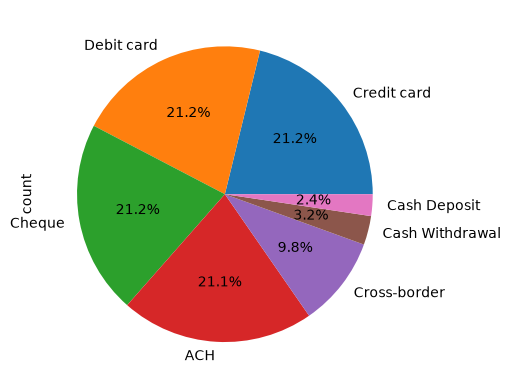

In [45]:
df['Payment_type'].value_counts().plot(kind='pie',autopct = '%.1f%%')

<Axes: xlabel='Is_laundering'>

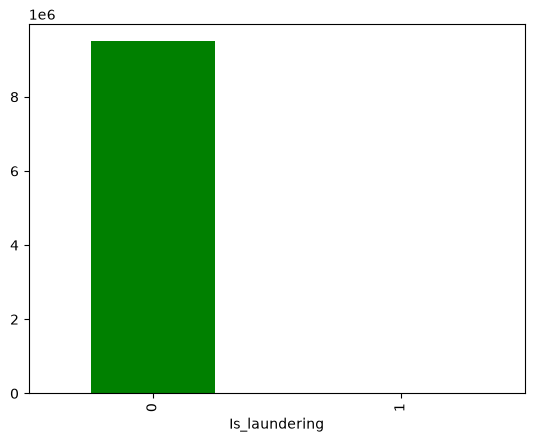

In [46]:
df['Is_laundering'].value_counts().plot(kind='bar',color=['green','red'])                  ### It is imbalanced Dataset

<Axes: xlabel='Laundering_type'>

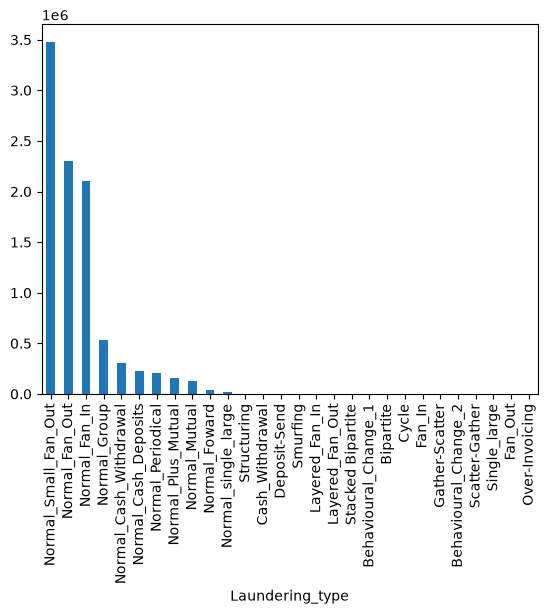

In [48]:
df['Laundering_type'].value_counts().plot(kind = 'bar')

<Axes: xlabel='Laundering_type'>

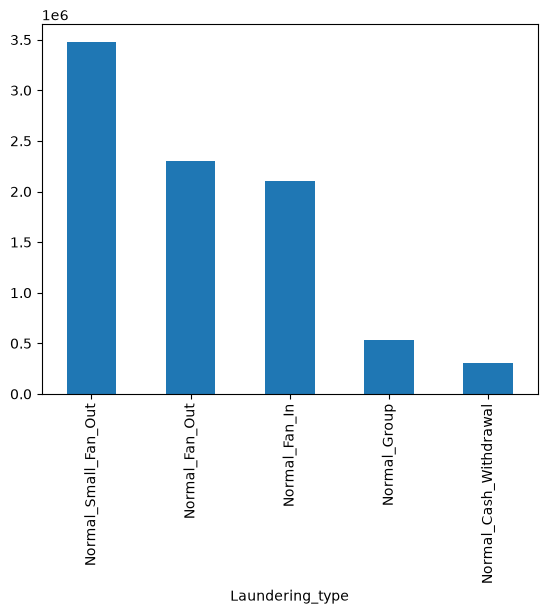

In [49]:
df['Laundering_type'].value_counts().nlargest(5).plot(kind='bar')

# Bivariate Analysis

In [50]:
# catgorical vs Catgorical

In [51]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

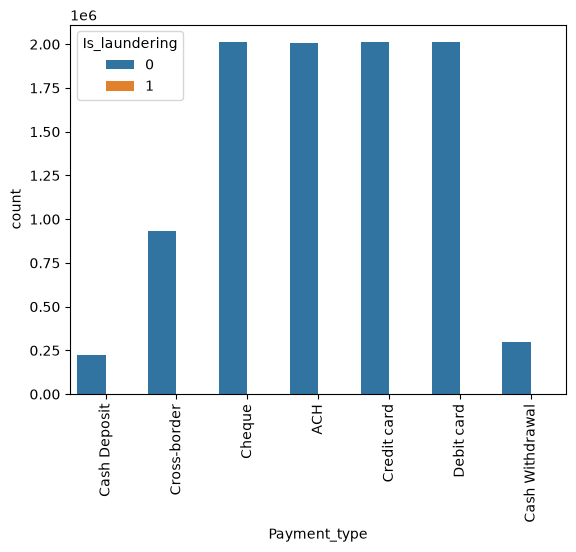

In [52]:
sns.countplot(x = df['Payment_type'], hue=df['Is_laundering'])
plt.xticks(rotation = 90)
plt.show()

In [53]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

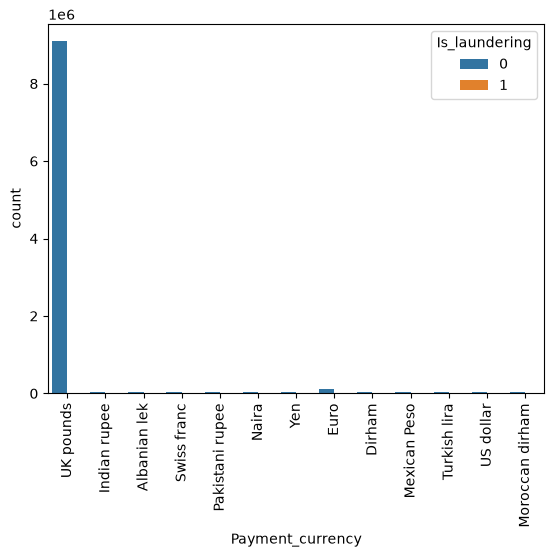

In [54]:
sns.countplot(x = df['Payment_currency'], hue=df['Is_laundering'])
plt.xticks(rotation = 90)
plt.show()

<Axes: xlabel='Is_laundering', ylabel='Amount'>

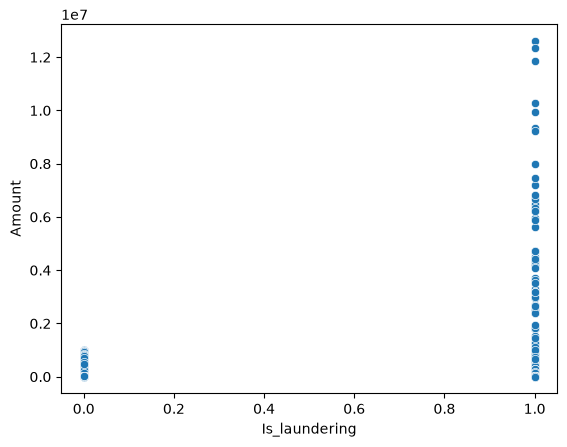

In [55]:
sns.scatterplot(x=df['Is_laundering'],y=df['Amount'])

In [ ]:
df.columns

In [ ]:
#Perform bivariate for more insights


# Data Cleaning

In [56]:
df.dtypes

Time                       object
Date                       object
Sender_account              int64
Receiver_account            int64
Amount                    float64
Payment_currency           object
Received_currency          object
Sender_bank_location       object
Receiver_bank_location     object
Payment_type               object
Is_laundering               int64
Laundering_type            object
dtype: object

In [58]:
df['Sender_account']=df['Sender_account'].astype('str')
df['Receiver_account']=df['Receiver_account'].astype('str')

In [59]:
df['Date']=df['Date'].astype('datetime64[ns]')

In [60]:
df['Date'].dt.year

0          2022
1          2022
2          2022
3          2022
4          2022
           ... 
9504847    2023
9504848    2023
9504849    2023
9504850    2023
9504851    2023
Name: Date, Length: 9504852, dtype: int32

In [61]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

In [62]:
df.drop(columns=['Time', 'Date', 'Laundering_type', 'Sender_account', 'Receiver_account'],inplace=True)

In [63]:
df= df.sample(n=100000,random_state=23)

In [64]:
df.shape

(100000, 7)

In [65]:
x=df.drop(columns=['Is_laundering'])
y=df['Is_laundering']

In [67]:
x.columns

Index(['Amount', 'Payment_currency', 'Received_currency',
       'Sender_bank_location', 'Receiver_bank_location', 'Payment_type'],
      dtype='object')

In [69]:
x['Payment_type'].unique()

array(['Cash Withdrawal', 'ACH', 'Cash Deposit', 'Cheque', 'Debit card',
       'Cross-border', 'Credit card'], dtype=object)

In [84]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from imblearn.pipeline import Pipeline 
from sklearn.compose import ColumnTransformer 
from imblearn.over_sampling import SMOTE 

In [71]:
cat_col = x.select_dtypes(include=['object']).columns
num_col = x.select_dtypes(exclude=['object']).columns

In [72]:
cat_col

Index(['Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type'],
      dtype='object')

In [73]:
num_col

Index(['Amount'], dtype='object')

In [74]:
cat_trans=Pipeline([('OHE',OneHotEncoder(dtype='int'))])

In [76]:
num_trans=Pipeline([('Scaling',StandardScaler())])

In [81]:
preprocess=ColumnTransformer([('cat_trans',cat_trans,cat_col),
                             ('num_trans',num_trans,num_col)])

In [82]:
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat_trans', ...), ('num_trans', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

In [85]:
resampling=Pipeline([('Preprocessing ',preprocess),
                    ('SMOTE',SMOTE(random_state=23))])

In [86]:
resampling 

,steps,"[('Preprocessing ', ...), ('SMOTE', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat_trans', ...), ('num_trans', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready fo

In [88]:
x_s,y_s=resampling.fit_resample(x,y)

# Model Building 

In [91]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense,BatchNormalization,Dropout

In [93]:
model=Sequential()

model.add(Input(shape=(x_s.shape[1],)))

model.add(Dense(units=16,activation='relu'))
model.add(Dense(units=8,activation='relu'))
model.add(Dense(units=4,activation='relu'))
model.add(Dense(units=2,activation='relu'))


model.add(Dense(units=1,activation='sigmoid'))

In [94]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [95]:
history=model.fit(x_s,y_s,epochs=30,validation_split=0.2)

Epoch 1/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - accuracy: 0.7868 - loss: 0.5018 - val_accuracy: 0.5403 - val_loss: 0.7982
Epoch 2/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.8052 - loss: 0.4408 - val_accuracy: 0.6118 - val_loss: 0.6507
Epoch 3/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8088 - loss: 0.4211 - val_accuracy: 0.6783 - val_loss: 0.5183
Epoch 4/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8093 - loss: 0.3891 - val_accuracy: 0.5256 - val_loss: 0.7270
Epoch 5/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8113 - loss: 0.3816 - val_accuracy: 0.6385 - val_loss: 0.5975
Epoch 6/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.8132 - loss: 0.3770 - val_accuracy: 0.5510 - val_loss: 0.6436
Epoch 7/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8148 - loss: 0.3737 - val_accuracy: 0.7359 - val_loss: 0.4688
Epoch 8/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8166 - loss: 0.3709

In [97]:
epochs=range(1,31)
train_loss=history.history['loss']
val_loss=history.history['val_loss']


# Hyperparameter Tuning 

In [114]:
import optuna 
from tensorflow.keras.optimizers import Adam,RMSprop,SGD
from tensorflow.keras.callbacks import EarlyStopping 

In [123]:
 
def objective(trial):

    # Search Space
    n_layers = trial.suggest_int('n_layers', 1, 4)

    learning_rate = trial.suggest_float(
        'learning_rate', 0.0001, 0.1, log=True
    )

    batch_size = trial.suggest_categorical(
        'batch_size', [16, 32, 64, 128, 256]
    )

    optimizer_name = trial.suggest_categorical(
        'optimizer', ['adam', 'rmsprop', 'sgd']
    )

    # Building the model
    model = Sequential()

    model.add(Input(shape=(x_s.shape[1],)))

    for i in range(n_layers):

        units = trial.suggest_int(f'units_layer_{i}', 2, 32)

        dropout_rate = trial.suggest_float(
            f'dropout_layer_{i}', 0.0, 0.6
        )

        activation = trial.suggest_categorical(
            f'activation_{i}', ['relu', 'tanh', 'sigmoid']
        )

        model.add(Dense(units=units, activation=activation))

        model.add(Dropout(rate=dropout_rate))

    model.add(Dense(1, activation='sigmoid'))

    # Optimizer
    if optimizer_name == 'adam':
        optimizer = Adam(learning_rate=learning_rate)

    elif optimizer_name == 'rmsprop':
        optimizer = RMSprop(learning_rate=learning_rate)

    else:
        optimizer = SGD(learning_rate=learning_rate)

    # Compile
    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    # Early stopping
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    # Training
    history = model.fit(
        x_s,
        y_s,
        validation_split=0.2,
        epochs=100,
        batch_size=batch_size,
        callbacks=[early_stop]
    )

    best_loss = min(history.history['val_loss'])

    trial.set_user_attr('best_val_loss', float(best_loss))

    return best_loss


In [124]:
study=optuna.create_study(direction = 'minimize',sampler=optuna.samplers.TPESampler())

[I 2026-11-12 16:10:24,726] A new study created in memory with name: no-name-9214a5dd-e725-47eb-b614-bdc2f99c721b


In [125]:
study.optimize(objective,n_trials=3)

Epoch 1/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.6693 - loss: 0.6128 - val_accuracy: 0.3010 - val_loss: 0.8985
Epoch 2/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7228 - loss: 0.5751 - val_accuracy: 0.4854 - val_loss: 0.8357
Epoch 3/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7317 - loss: 0.5610 - val_accuracy: 0.4877 - val_loss: 0.8420
Epoch 4/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7359 - loss: 0.5513 - val_accuracy: 0.4994 - val_loss: 0.8037
Epoch 5/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7420 - loss: 0.5448 - val_accuracy: 0.5131 - val_loss: 0.7898
Epoch 6/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7474 - loss: 0.5382 - val_accuracy: 0.5222 - val_loss: 0.7914
Epoch 7/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7530 - loss: 0.5333 - val_accuracy: 0.5399 - val_loss: 0.7730
Epoch 8/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7575 - loss: 0

[I 2026-11-12 16:12:37,040] Trial 0 finished with value: 0.7247173190116882 and parameters: {'n_layers': 1, 'learning_rate': 0.004687292436447316, 'batch_size': 64, 'optimizer': 'sgd', 'units_layer_0': 25, 'dropout_layer_0': 0.19002954059149907, 'activation_0': 'tanh'}. Best is trial 0 with value: 0.7247173190116882.


Epoch 1/100
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7543 - loss: 0.5534 - val_accuracy: 0.5292 - val_loss: 1.0633
Epoch 2/100
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7737 - loss: 0.5270 - val_accuracy: 0.5318 - val_loss: 0.8689
Epoch 3/100
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7757 - loss: 0.5222 - val_accuracy: 0.5341 - val_loss: 0.8112
Epoch 4/100
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7777 - loss: 0.5178 - val_accuracy: 0.5282 - val_loss: 0.8648
Epoch 5/100
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7792 - loss: 0.5151 - val_accuracy: 0.5367 - val_loss: 0.7340
Epoch 6/100
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7798 - loss: 0.5150 - val_accuracy: 0.5234 - val_loss: 0.8839
Epoch 7/100
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7804 - loss: 0.5134 - val_accuracy: 0.6092 - val_loss: 0.6834
Epoch 8/100
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7803 - loss: 0

[I 2026-11-12 16:13:18,027] Trial 1 finished with value: 0.6833750605583191 and parameters: {'n_layers': 4, 'learning_rate': 0.021774177948579287, 'batch_size': 128, 'optimizer': 'rmsprop', 'units_layer_0': 9, 'dropout_layer_0': 0.4469792293607417, 'activation_0': 'tanh', 'units_layer_1': 5, 'dropout_layer_1': 0.2855271123454998, 'activation_1': 'sigmoid', 'units_layer_2': 32, 'dropout_layer_2': 0.09018171950214372, 'activation_2': 'sigmoid', 'units_layer_3': 30, 'dropout_layer_3': 0.45427938794151157, 'activation_3': 'relu'}. Best is trial 1 with value: 0.6833750605583191.


Epoch 1/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 22s 2ms/step - accuracy: 0.7180 - loss: 0.6103 - val_accuracy: 0.7540 - val_loss: 0.4727
Epoch 2/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 19s 2ms/step - accuracy: 0.7290 - loss: 0.6018 - val_accuracy: 0.5021 - val_loss: 1.1014
Epoch 3/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 20s 2ms/step - accuracy: 0.7341 - loss: 0.5985 - val_accuracy: 0.5895 - val_loss: 1.0420
Epoch 4/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 19s 2ms/step - accuracy: 0.7378 - loss: 0.5968 - val_accuracy: 0.5578 - val_loss: 1.0261
Epoch 5/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 20s 2ms/step - accuracy: 0.7342 - loss: 0.5998 - val_accuracy: 0.5319 - val_loss: 1.1428
Epoch 6/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 20s 2ms/step - accuracy: 0.7387 - loss: 0.5962 - val_accuracy: 0.5804 - val_loss: 1.1161


[I 2026-11-12 16:15:19,209] Trial 2 finished with value: 0.4726610779762268 and parameters: {'n_layers': 3, 'learning_rate': 0.08411633018640673, 'batch_size': 16, 'optimizer': 'rmsprop', 'units_layer_0': 9, 'dropout_layer_0': 0.300010433840686, 'activation_0': 'tanh', 'units_layer_1': 20, 'dropout_layer_1': 0.23325087052395246, 'activation_1': 'relu', 'units_layer_2': 19, 'dropout_layer_2': 0.2681253814186945, 'activation_2': 'sigmoid'}. Best is trial 2 with value: 0.4726610779762268.


In [126]:
model = Sequential()

model.add(Input(shape =(x_s.shape[1],)))

model.add(Dense(units=14,activation='relu'))
model.add(Dense(units=14,activation='relu'))

model.add(Dense(units=1,activation='sigmoid'))

In [128]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [129]:
history=model.fit(x_s,y_s,epochs=30,validation_split=0.2)

Epoch 1/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - accuracy: 0.7763 - loss: 0.4842 - val_accuracy: 0.6020 - val_loss: 0.6087
Epoch 2/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8020 - loss: 0.4176 - val_accuracy: 0.6030 - val_loss: 0.6462
Epoch 3/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8092 - loss: 0.3953 - val_accuracy: 0.5963 - val_loss: 0.5936
Epoch 4/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8131 - loss: 0.3842 - val_accuracy: 0.6568 - val_loss: 0.5044
Epoch 5/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8158 - loss: 0.3746 - val_accuracy: 0.6548 - val_loss: 0.5458
Epoch 6/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.8173 - loss: 0.3690 - val_accuracy: 0.7588 - val_loss: 0.4423
Epoch 7/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8176 - loss: 0.3658 - val_accuracy: 0.6626 - val_loss: 0.5404
Epoch 8/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8180 - loss: 0.3628 

In [133]:
import pickle
import joblib

In [134]:
model.save('AML.keras')

In [135]:
joblib.dump(preprocess,'preprocessor')

['preprocessor']